
## Setup
### Settings

In [1]:
AUDIO_FILES = ["data/GAME_AUDIO.flac"]
OUT_DIR = "results"
REUSE_FEATURES = True #Reuse cached features

### Imports

In [2]:
import hashlib
import json
import os
import shutil
import subprocess
import sys
import tempfile
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view as swv
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")
%matplotlib inline
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
os.makedirs(OUT_DIR, exist_ok=True)

def save_and_show(fig, name):
    fig.savefig(os.path.join(OUT_DIR, name), dpi=140, bbox_inches="tight")
    plt.show()

### Configuration

In [3]:
CFG = dict(
    
    #framing
    win_sec=0.200,
    hop_sec=0.050,
    env_hop_sec=0.010,
    band_lo_hz=63.0,
    band_hi_hz=12500.0,

    #what a device should track and how it is scored
    ref_sec=1.0, #"true" level = A-weighted level over a centred 1 s window
    detector_sec=0.5, #a conventional level detector integrates the last 0.5 s
    tolerance_db=3.0, #estimate errors smaller than this count as inaudible
    big_error_db=6.0, #a clearly noticeable mismatch
    warm_sec=60.0, #first minute of each recording is not scored (context filling up)

    # forecasting
    device_lead_sec=1.0, #predictive devices follow the forecast of the level this far ahead
    skill_leads_sec=(0.5, 1.0, 2.0, 4.0),
    train_stride=5, #train on every 5th frame (0.25 s); neighbouring frames are near-copies
    n_blocks=8, #contiguous CV blocks per recording (when there are < 3 recordings)
    purge_sec=30.0, #training frames this close to a test block are dropped (+ lead + ref)
    gbm=dict(max_iter=250, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=50, l2_regularization=1.0),

    #inference
    n_budgets=12, #stability budgets between a 20 s and a 1 s conventional AGC
    block_sec=30.0,
    n_boot=2000,
    perms=40,
    min_shift_sec=60.0,
    
    #secondary-analysis definitions
    calm_sec=8.0, calm_rise_db=3.0, #calm = baseline moment: no >= 3 dB rise in the last 8 s, level not above its usual (last-minute median) by >= 3 dB, and no rise starting now
    anticipation_leads_sec=(1.0, 2.0, 4.0), #H2 only credits warnings at least 1 s ahead
    surge_db=6.0, #a surge = the level ahead is >= 6 dB above the detector now
    ev_pre_sec=4.0,
    ev_rise_sec=2.0,
    ev_hold_sec=3.0,
    ev_delta_db=6.0,
    ev_nms_sec=4.0,
    seed=20261026,
)

Constants

In [4]:
A_WEIGHT = {
    50: -30.2, 63: -26.2, 80: -22.5, 100: -19.1, 125: -16.1, 160: -13.4, 200: -10.9, 250: -8.6, 315: -6.6, 400: -4.8, 500: -3.2, 630: -1.9, 800: -0.8, 1000: 0.0, 1250: 0.6, 1600: 1.0, 2000: 1.2, 2500: 1.3, 3150: 1.2, 4000: 1.0, 5000: 0.5, 6300: -0.1, 8000: -1.1, 10000: -2.5, 12500: -4.3, 16000: -6.6,
}

OCTAVE_GROUPS = [(56, 112, "80Hz"), (112, 224, "160Hz"), (224, 448, "315Hz"), (448, 895, "630Hz"), (895, 1790, "1.25kHz"), (1790, 3580, "2.5kHz"), (3580, 7160, "5kHz"), (7160, 14300, "10kHz")]
TONAL_REGIONS = [(100, 500, "low"), (500, 2000, "mid"), (2000, 6000, "high")]
MOD_BANDS = [(0.5, 1.5, "slow"), (1.5, 3.0, "beat"), (3.0, 8.0, "syllabic")]

#controller designs
ONEPOLE_T = (0.25, 0.5, 1, 2, 3, 5, 8, 12, 15, 20, 30, 60, 120)
ATTACK_RELEASE = [(a, r) for a in (0.25, 0.5, 1, 2) for r in (2, 4, 8, 16, 32) if r > a]
ADAPTIVE = [(s, f, th) for s in (4, 8, 16, 32) for f in (0.25, 0.5, 1) for th in (3, 4.5, 6, 9)]
SWITCH_RAMP_DB = 2.0

FAMILIES = ("reactive", "level", "full")
FAMILY_LABEL = {"reactive": "reactive (best conventional AGC)", "level": "forecast: level history only", "full": "forecast: level + spectral cues"}
FAMILY_COLOR = {"reactive": "#6c757d", "level": "#f4a261", "full": "#1d6fa5"}

### Configuration check

In [5]:
def config_hash(cfg):
    return hashlib.sha256(json.dumps(cfg, sort_keys=True, default=str).encode()).hexdigest()[:12]

CONFIG_HASH = config_hash(CFG)
print(f"Config hash: {CONFIG_HASH}")

Config hash: 226a7c2a8694


## DSP/Audio Primitives

In [6]:
#Running-window statistics

def db(p):
    return 10.0 * np.log10(np.maximum(p, 1e-20))

def secs(sec, fs):
    return max(1, int(round(sec * fs)))

def trailing_mean(x, n):
    x = np.asarray(x, float)
    cs = np.cumsum(np.concatenate([np.zeros((1,) + x.shape[1:]), x]), axis=0)
    i = np.arange(len(x))
    lo = np.maximum(0, i + 1 - n)
    count = (i + 1 - lo).reshape((-1,) + (1,) * (x.ndim - 1))
    return (cs[i + 1] - cs[lo]) / count

def trailing_sd(x, n):
    x = np.asarray(x, float) - np.mean(x)
    m = trailing_mean(x, n)
    return np.sqrt(np.maximum(trailing_mean(x * x, n) - m * m, 0.0))

def trailing_slope(x, n):
    x = np.asarray(x, float) - np.mean(x)
    N = len(x)
    k = np.arange(N, dtype=float)
    cs = np.concatenate([[0.0], np.cumsum(x)])
    ck = np.concatenate([[0.0], np.cumsum(k * x)])
    i = np.arange(N)
    lo = np.maximum(0, i + 1 - n)
    m = (i + 1 - lo).astype(float)
    sx = cs[i + 1] - cs[lo]
    sjx = (ck[i + 1] - ck[lo]) - lo * sx
    sj, sjj = m * (m - 1) / 2, (m - 1) * m * (2 * m - 1) / 6
    with np.errstate(divide="ignore", invalid="ignore"):
        s = (m * sjx - sj * sx) / (m * sjj - sj * sj)
    s[~np.isfinite(s)] = 0.0
    return s

def trailing_max(x, n):
    xp = np.concatenate([np.full(n - 1, x[0]), x])
    return swv(xp, n).max(axis=1)

def window_mean(x, start, n):
    x = np.asarray(x, float)
    N = len(x)
    cs = np.concatenate([[0.0], np.cumsum(x)])
    a = np.arange(N) + start
    b = a + n
    out = np.full(N, np.nan)
    ok = (a >= 0) & (b <= N)
    out[ok] = (cs[b[ok]] - cs[a[ok]]) / n
    return out

def fill_nan(x):
    x = np.asarray(x, float).copy()
    ok = np.isfinite(x)
    if not ok.any():
        return np.zeros_like(x)
    idx = np.where(ok, np.arange(len(x)), 0)
    np.maximum.accumulate(idx, out=idx)
    x = x[idx]
    first = int(np.argmax(ok))
    x[:first] = x[first]
    return x

def seconds_since(flag, fs, cap):
    i = np.arange(len(flag))
    last = np.maximum.accumulate(np.where(flag, i, -1))
    return np.where(last >= 0, np.minimum((i - last) / fs, cap), cap)

In [7]:
#Statistics

def ci95(draws):
    draws = np.asarray(draws, float)
    draws = draws[np.isfinite(draws)]
    return (float(np.percentile(draws, 2.5)), float(np.percentile(draws, 97.5))) if len(draws) else (np.nan, np.nan)

def auc(score, positive):
    from scipy.stats import rankdata
    npos = int(positive.sum())
    nneg = len(positive) - npos
    if npos == 0 or nneg == 0:
        return np.nan
    r = rankdata(score)
    return float((r[positive].sum() - npos * (npos + 1) / 2) / (npos * nneg))

def count_episodes(mask_rows, t_rows, gap=5.0):
    tt = t_rows[mask_rows]
    return int(1 + (np.diff(tt) > gap).sum()) if len(tt) else 0

def fmt_p(p):
    return "<0.001" if p < 0.001 else f"{p:.3f}"

def mmss(sec):
    sec = int(round(sec))
    return f"{sec // 60:02d}:{sec % 60:02d}"

## Preprocessing

In [8]:
def third_octave_bands(lo, hi, sr):
    nominal = np.array(sorted(A_WEIGHT), float)
    exact = 1000.0 * 10 ** (np.round(10 * np.log10(nominal / 1000.0)) / 10.0)
    keep = (nominal >= lo - 1e-6) & (nominal <= hi + 1e-6) & (exact * 2 ** (1 / 6) < sr / 2)
    nominal, exact = nominal[keep], exact[keep]
    edges = np.stack([exact / 2 ** (1 / 6), exact * 2 ** (1 / 6)], axis=1)
    return nominal, exact, edges, np.array([A_WEIGHT[int(k)] for k in nominal])

def tonality(P):
    P = P.astype(np.float64) + 1e-30
    return np.log(P.mean(axis=1)) - np.log(P).mean(axis=1)

def ensure_readable(path):
    import soundfile as sf
    try:
        sf.info(path)
        return path, None
    except Exception:
        ff = shutil.which("ffmpeg")
        if not ff:
            sys.exit(f"Cannot read {path}. Convert it first, e.g.  ffmpeg -i in.m4a -c:a pcm_s24le out.wav")
        tmp = tempfile.mkdtemp()
        out = os.path.join(tmp, "converted.wav")
        print("  converting with ffmpeg ->", out)
        subprocess.run([ff, "-y", "-i", path, "-c:a", "pcm_s24le", out], check=True, capture_output=True)
        return out, tmp

In [9]:
def extract_audio_features(path, cfg):
    import soundfile as sf
    from scipy.fft import rfft
    info = sf.info(path)
    sr = info.samplerate
    win = int(round(cfg["win_sec"] * sr))
    hop = int(round(cfg["hop_sec"] * sr))
    ehop = int(round(cfg["env_hop_sec"] * sr))
    nfft = 1 << int(np.ceil(np.log2(win)))
    window = np.hanning(win).astype(np.float32)
    norm = float(np.sum(window.astype(np.float64) ** 2)) * nfft #periodogram -> mean-square power
    nominal, exact, edges, aw = third_octave_bands(cfg["band_lo_hz"], cfg["band_hi_hz"], sr)
    freqs = np.fft.rfftfreq(nfft, 1.0 / sr)
    onesided = np.full(len(freqs), 2.0)
    onesided[[0, -1]] = 1.0
    to_bands = np.zeros((len(freqs), len(exact)), np.float32)
    for j, (f1, f2) in enumerate(edges):
        sel = (freqs >= f1) & (freqs < f2)
        if not sel.any():
            sel = np.arange(len(freqs)) == np.argmin(np.abs(freqs - exact[j]))
        to_bands[sel, j] = onesided[sel]
    regions = [(name, (freqs >= lo) & (freqs < hi)) for lo, hi, name in TONAL_REGIONS if hi < sr / 2]
    bp, ton, env = [], [], []
    carry = np.zeros(0, np.float32)
    ecarry = np.zeros(0, np.float32)
    n_samp = n_clip = 0
    peak = 0.0
    mode = None
    t0 = time.time()
    with sf.SoundFile(path) as f:
        while True:
            x = f.read(ehop * 1000, dtype="float32", always_2d=True) #10s at a time
            if len(x) == 0:
                break
            if mode is None:
                mode = "mono"
                if x.shape[1] > 1:
                    c = np.corrcoef(x[:, 0], x[:, 1])[0, 1]
                    mode = "mean of channels" if (np.isfinite(c) and c > 0.95) else "first channel"
                    if mode == "first channel":
                        print(f"  NOTE: channels differ (corr={c:.2f}); using channel 1 only.")
            m = x.mean(axis=1) if mode == "mean of channels" else x[:, 0]
            n_samp += len(m)
            n_clip += int((np.abs(m) >= 0.999).sum())
            peak = max(peak, float(np.abs(m).max()))
            eb = np.concatenate([ecarry, m])
            ne = len(eb) // ehop
            env.append(np.sqrt(np.mean(eb[:ne * ehop].reshape(ne, ehop).astype(np.float64) ** 2, axis=1)))
            ecarry = eb[ne * ehop:]
            buf = np.concatenate([carry, m])
            if len(buf) < win:
                carry = buf
                continue
            nf = (len(buf) - win) // hop + 1
            spec = rfft(swv(buf, win)[::hop][:nf] * window, n=nfft, axis=1)
            P = (spec.real ** 2 + spec.imag ** 2) / norm
            bp.append(P @ to_bands)
            ton.append(np.column_stack([tonality(P[:, sel]) for _, sel in regions]))
            carry = buf[nf * hop:]
    env = np.concatenate(env)
    edb = 20 * np.log10(np.maximum(env, 1e-9))
    qc = dict(file=os.path.basename(path), sr=sr, channels=info.channels, channel_mode=mode, duration_s=n_samp / sr, clip_fraction=n_clip / max(n_samp, 1), peak=peak, noise_floor_dbfs=float(np.percentile(edb, 2)), loud_dbfs=float(np.percentile(edb, 99.9)), dynamic_range_db=float(np.percentile(edb, 99.5) - np.percentile(edb, 2)))
    out = dict(bp=np.concatenate(bp).astype(np.float32), tonal=np.concatenate(ton).astype(np.float32), env=env.astype(np.float32), nominal=nominal, exact=exact, aw=aw, tonal_names=[name for name, _ in regions], qc=qc)
    print(f"  {qc['file']}: {qc['duration_s'] / 60:.1f} min, {sr} Hz, {len(out['bp'])} frames x "
          f"{len(exact)} bands in {time.time() - t0:.0f}s")
    return out

In [10]:
def load_or_extract(path, out, cfg, reuse):
    keys = ("win_sec", "hop_sec", "env_hop_sec", "band_lo_hz", "band_hi_hz")
    tag = config_hash({k: cfg[k] for k in keys})
    cache = os.path.join(out, f"{os.path.splitext(os.path.basename(path))[0]}.features_{tag}.npz")
    if reuse and os.path.exists(cache):
        z = np.load(cache)
        F = {k: z[k] for k in ("bp", "tonal", "env", "nominal", "exact", "aw")}
        F["tonal_names"] = [str(s) for s in z["tonal_names"]]
        F["qc"] = json.loads(str(z["qc"]))
        print(f"  {F['qc']['file']}: reusing cached features ({os.path.basename(cache)})")
        return F
    readable, tmp = ensure_readable(path)
    try:
        F = extract_audio_features(readable, cfg)
    finally:
        if tmp:
            shutil.rmtree(tmp, ignore_errors=True)
    F["qc"]["file"] = os.path.basename(path)
    np.savez_compressed(cache, bp=F["bp"], tonal=F["tonal"], env=F["env"], nominal=F["nominal"], exact=F["exact"], aw=F["aw"], tonal_names=np.array(F["tonal_names"]), qc=json.dumps(F["qc"]))
    return F

In [11]:
audio_features = [load_or_extract(path, OUT_DIR, CFG, REUSE_FEATURES) for path in AUDIO_FILES]

  GAME_AUDIO.flac: 32.3 min, 48000 Hz, 38743 frames x 24 bands in 26s


## Feature Extraction (Spectral Shape)

In [12]:
def octave_groups(bp, nominal):
    G, names = [], []
    for lo, hi, name in OCTAVE_GROUPS:
        sel = (nominal >= lo) & (nominal < hi)
        if sel.any():
            G.append(bp[:, sel].sum(axis=1))
            names.append(name)
    return np.column_stack(G), names

def context_percentiles(lv1, fs, window_sec=60, qs=(20, 50, 80)):
    step = secs(1.0, fs)
    grid = lv1[::step]
    padded = np.concatenate([np.full(window_sec - 1, grid[0]), grid])
    q = np.percentile(swv(padded, window_sec), qs, axis=1)
    j = np.arange(len(lv1)) // step #the latest grid point at or before each frame
    return [row[j] for row in q]

def modulation_fractions(env, t, cfg):
    efs = 1.0 / cfg["env_hop_sec"]
    e = 20 * np.log10(np.maximum(env, 1e-9))
    mw = int(round(2.0 * efs))
    end = np.floor(t * efs + 1e-6).astype(int) #envelope samples complete by time t
    ok = np.flatnonzero((end >= mw) & (end <= len(e)))
    f = np.fft.rfftfreq(mw, 1.0 / efs)
    hann = np.hanning(mw)
    total = (f >= 0.5) & (f <= 20)
    out = np.full((len(t), len(MOD_BANDS)), np.nan)
    for c in range(0, len(ok), 2000):
        ii = ok[c:c + 2000]
        seg = e[(end[ii] - mw)[:, None] + np.arange(mw)]
        seg = seg - seg.mean(axis=1, keepdims=True)
        M = np.abs(np.fft.rfft(seg * hann, axis=1)) ** 2
        tot = M[:, total].sum(axis=1) + 1e-12
        for j, (lo, hi, _) in enumerate(MOD_BANDS):
            out[ii, j] = M[:, (f >= lo) & (f < hi)].sum(axis=1) / tot
    return np.column_stack([fill_nan(out[:, j]) for j in range(len(MOD_BANDS))])

In [13]:
def build_recording(F, cfg, leads):
    fs = 1.0 / cfg["hop_sec"]

    def n(sec):
        return secs(sec, fs)

    bp = np.maximum(F["bp"].astype(np.float64), 1e-20)
    N = len(bp)
    t = np.arange(N) * cfg["hop_sec"] + cfg["win_sec"] #when each frame becomes available
    P_a = (bp * 10 ** (F["aw"] / 10)).sum(axis=1)
    L_a = db(P_a)
    lv = {w: db(trailing_mean(P_a, n(w))) for w in (0.25, 0.5, 1, 2, 4, 8, 16)}
    cols, groups = {}, {}

    def add(group, name, values):
        cols[name] = np.asarray(values, float)
        groups.setdefault(group, []).append(name)

    #Everything a level-based device could know (relative dB, so gain-invariant)
    for a, b in ((0.25, 0.5), (0.25, 2), (0.5, 4), (1, 8), (2, 16)):
        add("level", f"rise_{a:g}s_vs_{b:g}s", lv[a] - lv[b])
    add("level", "slope_1s", trailing_slope(L_a, n(1)) * fs)
    add("level", "slope_4s", trailing_slope(L_a, n(4)) * fs)
    add("level", "fluct_2s", trailing_sd(L_a, n(2)))
    add("level", "fluct_8s", trailing_sd(L_a, n(8)))
    add("level", "peak_2s", trailing_max(L_a, n(2)) - lv[2])
    recent_level_peak = trailing_max(lv[0.25], n(5))
    add("level", "peak_5s_vs_16s", recent_level_peak - lv[16])
    add("level", "peak_5s_vs_now", recent_level_peak - lv[0.25])
    context = dict(zip((20, 50, 80), context_percentiles(lv[1], fs)))
    for q, v in context.items():
        add("level", f"vs_p{q}_last_minute", lv[1] - v)
    add("level", "log_time_since_rise", np.log1p(seconds_since(lv[1] - lv[16] > 6.0, fs, cap=120.0)))

    #Level-free descriptors of what is sounding
    def recent_peak(v):
        return trailing_max(trailing_mean(v, n(0.25)), n(5)) - trailing_mean(v, n(30))

    G, gnames = octave_groups(bp, F["nominal"])
    tot = G.sum(axis=1)
    rel_short = db(trailing_mean(G, n(0.5))) - db(trailing_mean(tot, n(0.5)))[:, None]
    rel_long = db(trailing_mean(G, n(4))) - db(trailing_mean(tot, n(4)))[:, None]
    rel_frame = db(G) - db(tot)[:, None]
    for j, g in enumerate(gnames):
        add("band shape", f"shape_{g}", rel_short[:, j])
        add("band shape", f"shape_change_{g}", rel_short[:, j] - rel_long[:, j])
        add("band shape", f"shape_recent_peak_{g}", recent_peak(rel_frame[:, j]))
    p = bp / bp.sum(axis=1, keepdims=True)
    logf = np.log2(F["exact"])
    centroid = p @ logf
    lag = n(0.2)
    flux = np.zeros(N)
    flux[lag:] = np.abs(p[lag:] - p[:-lag]).sum(axis=1)
    timbre = dict(centroid=centroid, spread=np.sqrt(np.maximum(p @ logf ** 2 - centroid ** 2, 0)), flatness=np.exp(np.log(p).mean(axis=1)) / p.mean(axis=1), flux=flux)
    for name, v in timbre.items():
        short, long_ = trailing_mean(v, n(0.5)), trailing_mean(v, n(4))
        add("timbre", name, short)
        add("timbre", f"{name}_change", short - long_)
        add("timbre", f"{name}_recent_peak", recent_peak(v if name != "flatness" else -v))
    for j, name in enumerate(F["tonal_names"]):
        v = F["tonal"][:, j].astype(float)
        short, long_ = trailing_mean(v, n(0.5)), trailing_mean(v, n(4))
        add("tonality", f"tonal_{name}", short)
        add("tonality", f"tonal_{name}_change", short - long_)
        add("tonality", f"tonal_{name}_recent_peak", recent_peak(v))
    mod = modulation_fractions(F["env"], t, cfg)
    for j, (_, _, name) in enumerate(MOD_BANDS):
        add("modulation", f"mod_{name}", mod[:, j])
        add("modulation", f"mod_{name}_recent_peak", recent_peak(mod[:, j]))
    shape_now = db(trailing_mean(bp, n(1)))
    shape_now -= shape_now.mean(axis=1, keepdims=True)
    for past in (8, 30):
        before = db(trailing_mean(bp, n(past)))
        before -= before.mean(axis=1, keepdims=True)
        before = before[np.maximum(np.arange(N) - n(1), 0)] #the past seconds before the last 1s
        add("novelty", f"novelty_vs_prev_{past}s", np.sqrt(((shape_now - before) ** 2).mean(axis=1)))

    h = n(cfg["ref_sec"] / 2)
    L_ref = db(window_mean(P_a, -h + 1, 2 * h)) # centred: NaN at the very ends
    L_now = db(trailing_mean(P_a, n(cfg["detector_sec"])))
    targets = {}
    for lead in leads:
        k = int(round(lead * fs))
        ahead = np.full(N, np.nan)
        ahead[:N - k] = L_ref[k:]
        targets[lead] = ahead - L_now
    calm = ((trailing_max(lv[1] - lv[16], n(cfg["calm_sec"])) < cfg["calm_rise_db"]) & (lv[1] - context[50] < cfg["calm_rise_db"]) & (lv[0.25] - lv[4] < 2.0))
    onsets, amps = detect_onsets(L_a, P_a, fs, cfg)
    return dict(t=t, P_a=P_a, L_a=L_a, L_ref=L_ref, L_now=L_now, L_quick=lv[0.25], lv1=lv[1], cols=cols, groups=groups, targets=targets, calm=calm, onsets=onsets, onset_amp=amps, qc=F["qc"])

In [14]:
def detect_onsets(L, P, fs, cfg):
    npre, nr, nh = (secs(cfg[k], fs) for k in ("ev_pre_sec", "ev_rise_sec", "ev_hold_sec"))
    N, delta = len(L), cfg["ev_delta_db"]
    ts = np.arange(npre, N - nr - nh)
    if len(ts) == 0:
        return np.zeros(0, int), np.zeros(0)
    base = np.median(swv(L, npre)[ts - npre], axis=1)
    rise = np.median(swv(L, nr)[ts], axis=1) - base
    hold = np.median(swv(L, nh)[ts + nr], axis=1) - base
    cand = np.flatnonzero((rise >= delta) & (hold >= 0.7 * delta))
    h = secs(0.25, fs)
    smooth = fill_nan(db(window_mean(P, -h + 1, 2 * h))) #centred 0.5 s, for timing only
    taken = np.zeros(N, bool)
    nms = secs(cfg["ev_nms_sec"], fs)
    onsets, amps = [], []
    for j in cand[np.argsort(-rise[cand])]:
        t0 = ts[j]
        if taken[t0]:
            continue
        taken[max(0, t0 - nms):t0 + nms] = True
        seg = smooth[t0:t0 + nr + nh]
        amp = float(seg.max() - base[j])
        onsets.append(t0 + int(np.argmax(seg >= base[j] + 0.5 * amp)))
        amps.append(amp)
    order = np.argsort(onsets)
    return np.array(onsets, int)[order], np.array(amps)[order]

In [15]:
def combine(recs, cfg, leads):
    names = [k for k in recs[0]["cols"] if all(k in r["cols"] for r in recs)]
    groups = {g: [m for m in ms if m in names] for g, ms in recs[0]["groups"].items()}
    groups = {g: ms for g, ms in groups.items() if ms}
    order = [m for ms in groups.values() for m in ms]
    col = {m: i for i, m in enumerate(order)}
    D = dict(fs=1.0 / cfg["hop_sec"], names=order, groups={g: [col[m] for m in ms] for g, ms in groups.items()})
    X = np.concatenate([np.column_stack([r["cols"][m] for m in order]) for r in recs])
    bad = ~np.isfinite(X)
    if bad.any():
        print(f"  NOTE: {bad.sum()} non-finite feature values set to 0")
    D["X"] = np.nan_to_num(X).astype(np.float32)
    D["level_cols"] = D["groups"]["level"]
    D["spectral_cols"] = [i for g, ix in D["groups"].items() if g != "level" for i in ix]
    for k in ("t", "P_a", "L_a", "L_ref", "L_now", "L_quick", "lv1", "calm"):
        D[k] = np.concatenate([r[k] for r in recs])
    D["targets"] = {lead: np.concatenate([r["targets"][lead] for r in recs]) for lead in leads}
    sizes = [len(r["t"]) for r in recs]
    starts = np.concatenate([[0], np.cumsum(sizes)[:-1]]).astype(int)
    D["bounds"] = [(int(s), int(s + z)) for s, z in zip(starts, sizes)]
    D["rec"] = np.repeat(np.arange(len(recs)), sizes)
    D["onsets"] = np.concatenate([r["onsets"] + s for r, s in zip(recs, starts)]).astype(int)
    D["onset_amp"] = np.concatenate([r["onset_amp"] for r in recs])
    D["qc"] = [r["qc"] for r in recs]

    #scoring rows (after warm-up, reference defined) and contiguous ~30s bootstrap blocks
    N = len(D["t"])
    scored = (D["t"] >= cfg["warm_sec"]) & np.isfinite(D["L_ref"])
    bid = np.full(N, -1)
    nb = 0
    for a, b in D["bounds"]:
        loc = np.flatnonzero(scored[a:b]) + a
        if len(loc) == 0:
            continue
        k = np.floor((D["t"][loc] - D["t"][loc[0]]) / cfg["block_sec"]).astype(int)
        if k.max() > 0 and (k == k.max()).sum() < 0.5 * (k == 0).sum():
            k[k == k.max()] -= 1 #merge a short final block
        bid[loc] = nb + k
        nb += int(k.max()) + 1
    D.update(scored=scored, bid=bid, n_blocks=nb, idx=np.flatnonzero(scored))
    eb = bid[D["idx"]]
    D["block_starts"] = np.concatenate([[0], np.flatnonzero(np.diff(eb)) + 1])
    D["block_count"] = np.bincount(eb, minlength=nb).astype(float)
    D["rec_starts"] = [a for a, _ in D["bounds"]]
    return D

In [16]:
LEADS = sorted(set(CFG["skill_leads_sec"]) | {CFG["device_lead_sec"]} | set(CFG["anticipation_leads_sec"]))
recordings = [build_recording(F, CFG, LEADS) for F in audio_features]
D = combine(recordings, CFG, LEADS)

lines = ["| family | kind | features | examples |", "|---|---|---|---|"]
for family, cols in D["groups"].items():
    names = [D["names"][c] for c in cols]
    kind = "level history" if family == "level" else "spectral cue"
    lines.append(f"| {family} | {kind} | {len(cols)} | {', '.join(names[:3])}, ... |")
display(Markdown("\n".join(lines)))
print(f"{len(D['t'])} frames ({len(D['t']) / D['fs'] / 60:.1f} min); {len(D['level_cols'])} level-history and "
      f"{len(D['spectral_cols'])} spectral features; calm moments: {100 * D['calm'][D['scored']].mean():.0f}% of the "
      f"scored time; {len(D['onsets'])} sustained rises >= {CFG['ev_delta_db']:g} dB.")

| family | kind | features | examples |
|---|---|---|---|
| level | level history | 16 | rise_0.25s_vs_0.5s, rise_0.25s_vs_2s, rise_0.5s_vs_4s, ... |
| band shape | spectral cue | 24 | shape_80Hz, shape_change_80Hz, shape_recent_peak_80Hz, ... |
| timbre | spectral cue | 12 | centroid, centroid_change, centroid_recent_peak, ... |
| tonality | spectral cue | 9 | tonal_low, tonal_low_change, tonal_low_recent_peak, ... |
| modulation | spectral cue | 6 | mod_slow, mod_slow_recent_peak, mod_beat, ... |
| novelty | spectral cue | 2 | novelty_vs_prev_8s, novelty_vs_prev_30s, ... |

38743 frames (32.3 min); 16 level-history and 53 spectral features; calm moments: 47% of the scored time; 41 sustained rises >= 6 dB.



## A first look

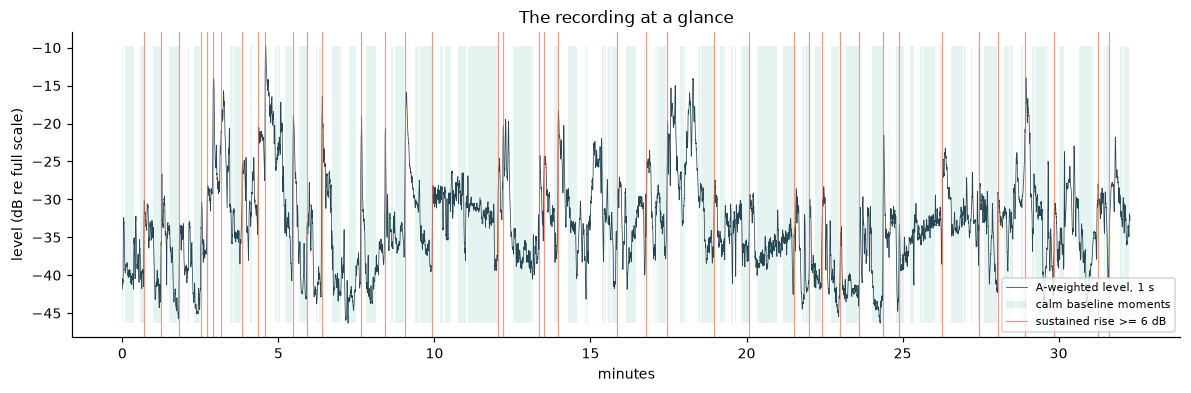

In [17]:
def plot_overview(D, cfg):
    tmin = D["t"] / 60
    fig, ax = plt.subplots(figsize=(13, 3.6))
    ax.plot(tmin, D["lv1"], color="#264653", lw=0.5, label="A-weighted level, 1 s")
    ax.fill_between(tmin, np.nanmin(D["lv1"]), np.nanmax(D["lv1"]), where=D["calm"], color="#2a9d8f", alpha=0.12, lw=0, label="calm baseline moments")
    for k, e in enumerate(D["onsets"]):
        ax.axvline(tmin[e], color="#e76f51", lw=0.8, alpha=0.7, label=f"sustained rise >= {cfg['ev_delta_db']:g} dB" if k == 0 else None)
    for a, _ in D["bounds"][1:]:
        ax.axvline(tmin[a], color="k", lw=1.5)
    ax.set_xlabel("minutes")
    ax.set_ylabel("level (dB re full scale)")
    ax.set_title("The recording at a glance")
    ax.legend(fontsize=7, loc="lower right")
    save_and_show(fig, "fig1_overview.png")

plot_overview(D, CFG)

## Forecasting


### Data Splits

In [18]:
def make_splits(D, cfg, max_lead):
    t, n_rec = D["t"], len(D["bounds"])
    if n_rec >= 3:
        fold = D["rec"].copy()
    else:
        fold = np.empty(len(t), int)
        for a, b in D["bounds"]:
            u = (t[a:b] - t[a]) / (t[b - 1] - t[a] + 1e-9)
            fold[a:b] = np.minimum((u * cfg["n_blocks"]).astype(int), cfg["n_blocks"] - 1)
    trainable = (np.arange(len(t)) % cfg["train_stride"] == 0) & (t >= cfg["warm_sec"])
    purge = cfg["purge_sec"] + max_lead + cfg["ref_sec"]
    splits = []
    for k in np.unique(fold):
        test = fold == k
        train = trainable & ~test
        if n_rec < 3:
            for a, b in D["bounds"]:
                tm = test[a:b]
                if tm.any():
                    lo, hi = t[a:b][tm].min() - purge, t[a:b][tm].max() + purge
                    train[a:b] &= ~((t[a:b] > lo) & (t[a:b] < hi))
        splits.append((np.flatnonzero(train), np.flatnonzero(test)))
    return splits

def new_model(cfg):
    from sklearn.ensemble import HistGradientBoostingRegressor
    return HistGradientBoostingRegressor(random_state=cfg["seed"], early_stopping=False, **cfg["gbm"])

def oof_forecast(X, y, splits, cfg):
    pred = np.full(len(y), np.nan)
    clim = np.full(len(y), np.nan)
    models = []
    for tr, te in splits:
        tr = tr[np.isfinite(y[tr])]
        model = new_model(cfg).fit(X[tr], y[tr])
        pred[te] = model.predict(X[te])
        clim[te] = y[tr].mean()
        models.append(model)
    return pred, clim, models

### Training

In [19]:
splits = make_splits(D, CFG, max(LEADS))
preds = {}
t0 = time.time()
for lead in LEADS:
    y = D["targets"][lead]
    p_level, clim, _ = oof_forecast(D["X"][:, D["level_cols"]], y, splits, CFG)
    p_full, _, models = oof_forecast(D["X"], y, splits, CFG)
    preds[lead] = dict(level=p_level, full=p_full, clim=clim, models=models)
    print(f"lead {lead:g} s trained ({time.time() - t0:.0f} s)")

lead 0.5 s trained (23 s)
lead 1 s trained (33 s)
lead 2 s trained (44 s)
lead 4 s trained (54 s)


### Spectral Cues

In [20]:
def forecast_skill(D, preds, W, cfg):
    N = len(D["t"])
    rows = D["scored"] & (np.arange(N) % cfg["train_stride"] == 0)
    B, bid = D["n_blocks"], D["bid"]
    blocks = [np.flatnonzero(bid[rows] == b) for b in range(B)]
    out = []
    for lead, P in preds.items():
        y = D["targets"][lead]
        row = dict(lead=lead)
        for subset, mask in (("all", rows), ("calm", rows & D["calm"])):
            m = mask & np.isfinite(y) & np.isfinite(P["clim"])
            ssc = np.bincount(bid[m], (y[m] - P["clim"][m]) ** 2, B)
            sse = {k: np.bincount(bid[m], (y[m] - P[k][m]) ** 2, B) for k in ("level", "full")}
            sse["none"] = np.bincount(bid[m], y[m] ** 2, B)
            r2 = {k: 1 - (W @ v) / (W @ ssc) for k, v in sse.items()}
            row[subset] = dict(n=int(m.sum()), r2_level=float(r2["level"][0]), r2_full=float(r2["full"][0]), dr2=float(r2["full"][0] - r2["level"][0]), dr2_ci=ci95(r2["full"][1:] - r2["level"][1:]), rmse={k: float(np.sqrt(v.sum() / m.sum())) for k, v in sse.items()})
        m = rows & D["calm"] & np.isfinite(y)
        pos = y >= cfg["surge_db"]
        res = dict(n_pos=int((m & pos).sum()), n_episodes=count_episodes((m & pos)[rows], D["t"][rows]))
        if res["n_pos"] >= 10:
            sel = np.flatnonzero(m[rows])
            yr, sl, sf_ = y[rows][sel], P["level"][rows][sel], P["full"][rows][sel]
            lab = yr >= cfg["surge_db"]
            res.update(auc_level=auc(sl, lab), auc_full=auc(sf_, lab))
            pos_in_sel = {b: np.flatnonzero(np.isin(sel, blocks[b])) for b in range(B)}
            diffs = []
            for w in W[1:1 + min(1000, len(W) - 1)]:
                ix = np.concatenate([np.tile(pos_in_sel[b], c) for b, c in enumerate(w.astype(int)) if c] or [[]]).astype(int)
                if lab[ix].any() and not lab[ix].all():
                    diffs.append(auc(sf_[ix], lab[ix]) - auc(sl[ix], lab[ix]))
            res["diff_ci"] = ci95(diffs)
        row["calm_surge"] = res
        out.append(row)
    return out

In [21]:
rng = np.random.default_rng(CFG["seed"])
B = D["n_blocks"]
W = np.vstack([np.ones(B), rng.multinomial(B, np.full(B, 1.0 / B), size=CFG["n_boot"])])
skill = forecast_skill(D, preds, W, CFG)

lines = ["| lead | RMSE: no change | RMSE: level-only | RMSE: level + spectral | R2 level-only | R2 level + spectral " "| **added R2 from spectral cues** [95% CI] |", "|---|---|---|---|---|---|---|"]
for s in skill:
    a = s["all"]
    lines.append(f"| {s['lead']:g} s | {a['rmse']['none']:.2f} dB | {a['rmse']['level']:.2f} dB | {a['rmse']['full']:.2f} dB "
                 f"| {a['r2_level']:.3f} | {a['r2_full']:.3f} | **{a['dr2']:+.3f}** [{a['dr2_ci'][0]:+.3f}, {a['dr2_ci'][1]:+.3f}] |")
display(Markdown("\n".join(lines)))

| lead | RMSE: no change | RMSE: level-only | RMSE: level + spectral | R2 level-only | R2 level + spectral | **added R2 from spectral cues** [95% CI] |
|---|---|---|---|---|---|---|
| 0.5 s | 2.23 dB | 2.17 dB | 2.12 dB | 0.046 | 0.096 | **+0.051** [+0.016, +0.081] |
| 1 s | 2.96 dB | 2.96 dB | 2.86 dB | -0.002 | 0.063 | **+0.065** [+0.014, +0.113] |
| 2 s | 3.91 dB | 3.91 dB | 3.73 dB | -0.001 | 0.092 | **+0.094** [+0.031, +0.154] |
| 4 s | 4.95 dB | 4.90 dB | 4.61 dB | 0.022 | 0.133 | **+0.111** [+0.035, +0.192] |

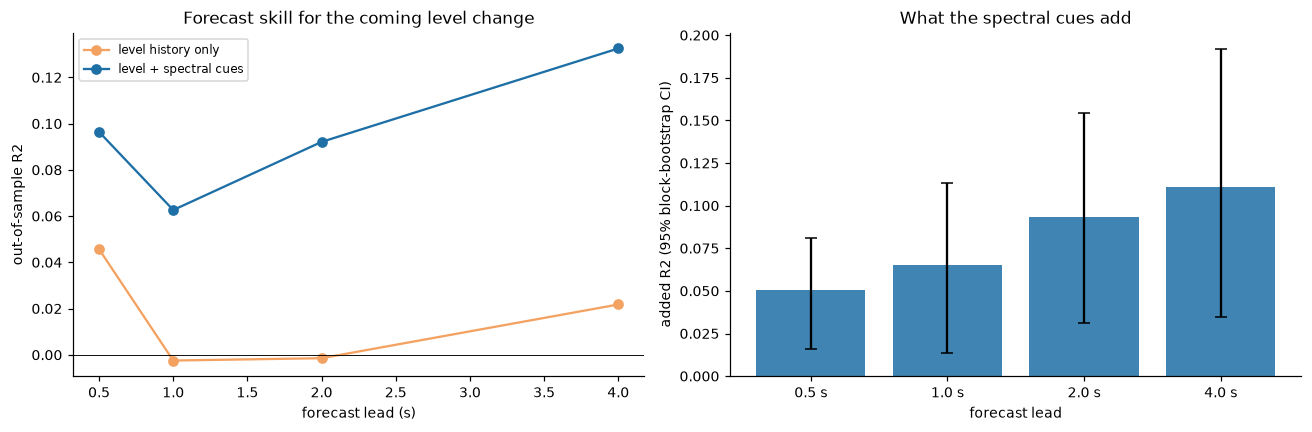

In [22]:
def plot_skill(skill):
    leads = [s["lead"] for s in skill]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(leads, [s["all"]["r2_level"] for s in skill], "o-", color=FAMILY_COLOR["level"], label="level history only")
    ax[0].plot(leads, [s["all"]["r2_full"] for s in skill], "o-", color=FAMILY_COLOR["full"], label="level + spectral cues")
    ax[0].axhline(0, color="k", lw=0.6)
    ax[0].set_xlabel("forecast lead (s)")
    ax[0].set_ylabel("out-of-sample R2")
    ax[0].set_title("Forecast skill for the coming level change")
    ax[0].legend(fontsize=8)
    gain = np.array([s["all"]["dr2"] for s in skill])
    lo = np.array([s["all"]["dr2_ci"][0] for s in skill])
    hi = np.array([s["all"]["dr2_ci"][1] for s in skill])
    ax[1].bar([str(l) + " s" for l in leads], gain, color=FAMILY_COLOR["full"], alpha=0.85)
    ax[1].errorbar(range(len(leads)), gain, yerr=[gain - lo, hi - gain], fmt="none", color="k", capsize=4)
    ax[1].axhline(0, color="k", lw=0.6)
    ax[1].set_xlabel("forecast lead")
    ax[1].set_ylabel("added R2 (95% block-bootstrap CI)")
    ax[1].set_title("What the spectral cues add")
    fig.tight_layout()
    save_and_show(fig, "fig2_forecast_skill.png")


plot_skill(skill)


## More on Spectral Cues

In [23]:
def cue_importance(D, P, y, splits, cfg, rng, repeats=3):
    rows = D["scored"] & (np.arange(len(y)) % cfg["train_stride"] == 0) & np.isfinite(y)

    def r2(pred):
        return 1 - np.sum((y[rows] - pred[rows]) ** 2) / np.sum((y[rows] - P["clim"][rows]) ** 2)

    base = r2(P["full"])
    ms = secs(30.0, D["fs"])
    drop = {}
    for g, cols in D["groups"].items():
        scores = []
        for _ in range(repeats):
            pred = np.full(len(y), np.nan)
            for (_, te), model in zip(splits, P["models"]):
                Xt = D["X"][te].copy()
                s = int(rng.integers(ms, len(te) - ms)) if len(te) > 2 * ms else len(te) // 2
                Xt[:, cols] = np.roll(Xt[:, cols], s, axis=0)
                pred[te] = model.predict(Xt)
            scores.append(r2(pred))
        drop[g] = float(base - np.mean(scores))
    return dict(base_r2=float(base), drop=drop)

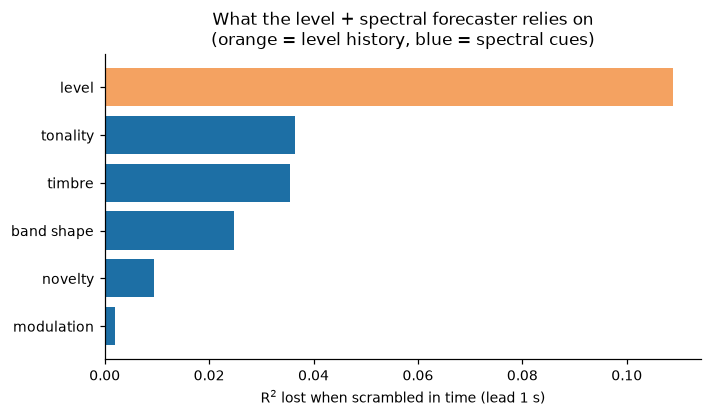

Spectral cue families, most to least used: tonality (+0.036), timbre (+0.035), band shape (+0.025), novelty (+0.009), modulation (+0.002)


In [24]:
importance = cue_importance(D, preds[CFG["device_lead_sec"]], D["targets"][CFG["device_lead_sec"]], splits, CFG, rng)

def plot_importance(importance, cfg):
    drop = importance["drop"]
    order = sorted(drop, key=lambda g: drop[g])
    colors = [FAMILY_COLOR["level"] if g == "level" else FAMILY_COLOR["full"] for g in order]
    fig, ax = plt.subplots(figsize=(7, 3.6))
    ax.barh(order, [drop[g] for g in order], color=colors)
    ax.set_xlabel(f"R$^2$ lost when scrambled in time (lead {cfg['device_lead_sec']:g} s)")
    ax.set_title("What the level + spectral forecaster relies on\n(orange = level history, blue = spectral cues)")
    save_and_show(fig, "fig3_cue_importance.png")

plot_importance(importance, CFG)
spectral = {g: v for g, v in importance["drop"].items() if g != "level"}
top = sorted(spectral, key=lambda g: -spectral[g])
print("Spectral cue families, most to least used: " + ", ".join(f"{g} ({spectral[g]:+.3f})" for g in top))

## Headline Tests

In [25]:
def calm_stats(y, pred, clim, rows, surge_db):
    m = rows & np.isfinite(y)
    r2 = 1 - np.sum((y[m] - pred[m]) ** 2) / np.sum((y[m] - clim[m]) ** 2)
    surge = y[m] >= surge_db
    a = auc(pred[m], surge) if 10 <= surge.sum() < len(surge) else np.nan
    return np.array([r2, a])

def shifted_spectral_null(D, splits, preds, rows, level_stats, n_perms, cfg, rng):
    leads = list(preds)
    ms = secs(cfg["min_shift_sec"], D["fs"])
    null = np.zeros((n_perms, 2, len(leads)))
    t0 = time.time()
    for k in range(n_perms):
        X = D["X"].copy()
        for a, b in D["bounds"]:
            L = b - a
            s = int(rng.integers(ms, L - ms)) if L > 2 * ms else L // 2
            X[a:b, D["spectral_cols"]] = np.roll(X[a:b, D["spectral_cols"]], s, axis=0)
        for j, lead in enumerate(leads):
            y = D["targets"][lead]
            p, clim, _ = oof_forecast(X, y, splits, cfg)
            null[k, :, j] = calm_stats(y, p, clim, rows, cfg["surge_db"]) - level_stats[lead]
        if (k + 1) % 5 == 0 or k + 1 == n_perms:
            print(f"    refit {k + 1}/{n_perms} ({time.time() - t0:.0f}s)", flush=True)
    return null.reshape(n_perms, -1)

In [26]:
def anticipation_test(D, splits, preds, cfg, rng, null=None):
    N = len(D["t"])
    rows = D["scored"] & D["calm"] & (np.arange(N) % cfg["train_stride"] == 0)
    preds = {l: preds[l] for l in cfg["anticipation_leads_sec"]}
    leads = list(preds)
    stats = {f: {l: calm_stats(D["targets"][l], preds[l][f], preds[l]["clim"], rows, cfg["surge_db"]) for l in leads} for f in ("level", "full")}
    obs = np.concatenate([[stats["full"][l][s] - stats["level"][l][s] for l in leads] for s in (0, 1)])
    if null is None:
        null = shifted_spectral_null(D, splits, preds, rows, stats["level"], cfg["perms"], cfg, rng)
    valid = np.isfinite(obs) & np.isfinite(null).all(axis=0)
    mu, sd = null.mean(axis=0), null.std(axis=0) + 1e-12
    z = np.where(valid, (obs - mu) / sd, -np.inf)
    zmax_null = np.where(valid, (null - mu) / sd, -np.inf).max(axis=1)
    K, best = len(null), int(np.argmax(z))
    nl = len(leads)
    return dict(leads=leads, obs_r2=obs[:nl], obs_auc=obs[nl:], z_r2=z[:nl], z_auc=z[nl:], null=null, band=np.percentile(null, [2.5, 97.5], axis=0), crit=float(np.percentile(zmax_null, 95)), best=("R2" if best < nl else "AUC", leads[best % nl], float(obs[best]), float(z[best])), p_omni=float((1 + np.sum(zmax_null >= z[best])) / (1 + K)), best_positive=bool(obs[best] > 0))

In [27]:
H2 = anticipation_test(D, splits, preds, CFG, rng)

    refit 5/40 (97s)
    refit 10/40 (193s)
    refit 15/40 (290s)
    refit 20/40 (386s)
    refit 25/40 (483s)
    refit 30/40 (579s)
    refit 35/40 (676s)
    refit 40/40 (773s)


In [28]:
def null_max_z(H2):
    null = H2["null"]
    mu, sd = null.mean(axis=0), null.std(axis=0) + 1e-12
    obs = np.concatenate([H2["obs_r2"], H2["obs_auc"]])
    valid = np.isfinite(obs) & np.isfinite(null).all(axis=0)
    return np.where(valid, (null - mu) / sd, -np.inf).max(axis=1)

zmax_null = null_max_z(H2)
stat, best_lead, best_gain, best_z = H2["best"]
n_beaten = int(np.sum(zmax_null < best_z))
supported = H2["best_positive"] and H2["p_omni"] <= 0.05

calm_rows = {s["lead"]: s for s in skill}
lines = ["| lead | calm R2: level-only → +spectral | R2 gain (z) | surge AUC: level-only → +spectral [CI of gain] | AUC gain (z) |",
         "|---|---|---|---|---|"]
for j, lead in enumerate(H2["leads"]):
    c, cs = calm_rows[lead]["calm"], calm_rows[lead]["calm_surge"]
    auc_txt = (f"{cs['auc_level']:.2f} → **{cs['auc_full']:.2f}** [{cs['diff_ci'][0]:+.2f}, {cs['diff_ci'][1]:+.2f}]" if "auc_level" in cs else "too few surges")
    lines.append(f"| {lead:g} s | {c['r2_level']:.3f} → {c['r2_full']:.3f} | {H2['obs_r2'][j]:+.3f} ({H2['z_r2'][j]:.1f}) " f"| {auc_txt} | {H2['obs_auc'][j]:+.3f} ({H2['z_auc'][j]:.1f}) |")
display(Markdown("\n".join(lines)))
display(Markdown(
    f"**Strongest early warning:** {stat} at {best_lead:g} s ahead, gain {best_gain:+.3f}, z = {best_z:.1f} "
    f"(family-wise 95% threshold z = {H2['crit']:.1f}).  \n"
    f"**The observed result beats {n_beaten} of {len(zmax_null)} shifted-cue refits: permutation p = {fmt_p(H2['p_omni'])}"))

| lead | calm R2: level-only → +spectral | R2 gain (z) | surge AUC: level-only → +spectral [CI of gain] | AUC gain (z) |
|---|---|---|---|---|
| 1 s | -0.031 → 0.041 | +0.073 (3.3) | 0.62 → **0.73** [+0.05, +0.19] | +0.112 (3.1) |
| 2 s | 0.007 → 0.087 | +0.081 (3.6) | 0.66 → **0.77** [+0.04, +0.18] | +0.103 (4.4) |
| 4 s | 0.051 → 0.192 | +0.142 (4.8) | 0.66 → **0.79** [+0.08, +0.19] | +0.132 (5.5) |

**Strongest early warning:** AUC at 4 s ahead, gain +0.132, z = 5.5 (family-wise 95% threshold z = 2.1).  
**The observed result beats 40 of 40 shifted-cue refits: permutation p = 0.024

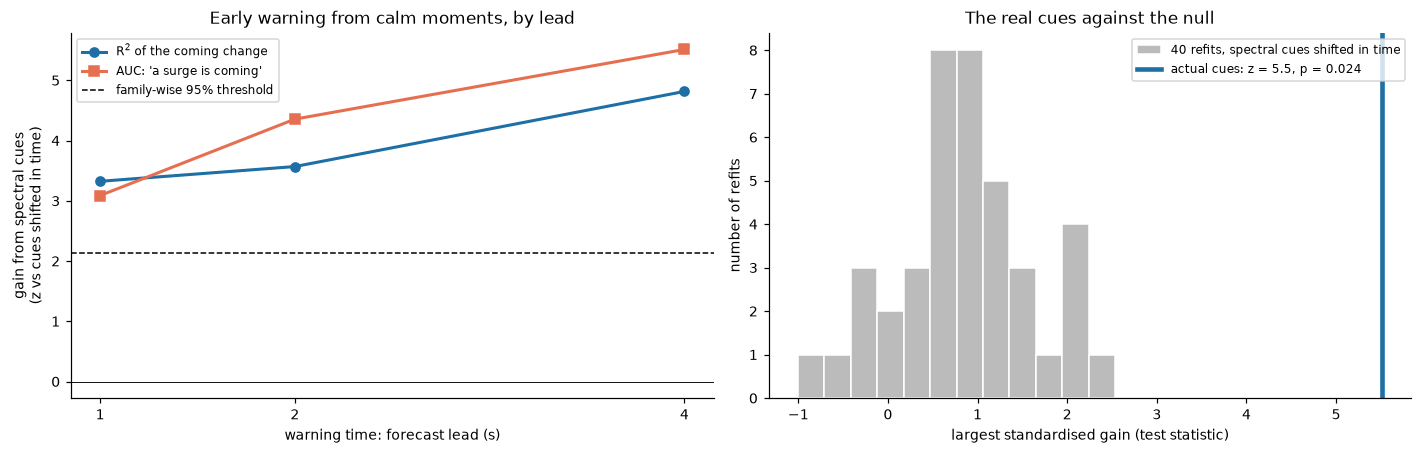

In [29]:
def plot_early_warning(H2, zmax_null):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
    ax[0].plot(H2["leads"], H2["z_r2"], "o-", lw=2, color=FAMILY_COLOR["full"], label="R$^2$ of the coming change")
    ax[0].plot(H2["leads"], H2["z_auc"], "s-", lw=2, color="#e76f51", label="AUC: 'a surge is coming'")
    ax[0].axhline(H2["crit"], color="k", ls="--", lw=1, label="family-wise 95% threshold")
    ax[0].axhline(0, color="k", lw=0.6)
    ax[0].set_xticks(H2["leads"])
    ax[0].set_xlabel("warning time: forecast lead (s)")
    ax[0].set_ylabel("gain from spectral cues\n(z vs cues shifted in time)")
    ax[0].set_title("Early warning from calm moments, by lead")
    ax[0].legend(fontsize=8)
    ax[1].hist(zmax_null, bins=12, color="#bbbbbb", edgecolor="white", label=f"{len(zmax_null)} refits, spectral cues shifted in time")
    ax[1].axvline(H2["best"][3], color=FAMILY_COLOR["full"], lw=3, label=f"actual cues: z = {H2['best'][3]:.1f}, p = {fmt_p(H2['p_omni'])}")
    ax[1].set_xlabel("largest standardised gain (test statistic)")
    ax[1].set_ylabel("number of refits")
    ax[1].set_title("The real cues against the null")
    ax[1].legend(fontsize=8)
    fig.tight_layout()
    save_and_show(fig, "fig4_early_warning_test.png")

plot_early_warning(H2, zmax_null)

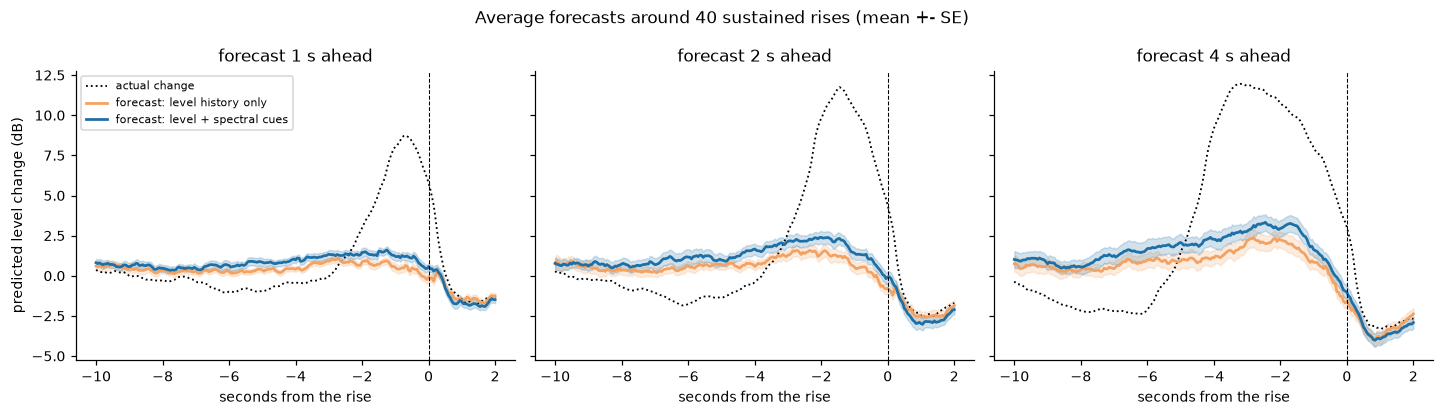

In [30]:
def plot_forecasts_around_rises(D, preds, leads, cfg):
    fs = D["fs"]
    lags = np.arange(-secs(10, fs), secs(2, fs) + 1)
    N = len(D["t"])
    ok = [e for e in D["onsets"] if e + lags[0] >= 0 and e + lags[-1] < N and D["rec"][e + lags[0]] == D["rec"][e + lags[-1]] and D["scored"][e + lags[0]]]
    if not ok:
        print("No rises with a complete window.")
        return
    idx = np.array(ok)[:, None] + lags[None, :]
    fig, axs = plt.subplots(1, len(leads), figsize=(4.4 * len(leads), 3.8), sharey=True)
    for ax, lead in zip(np.atleast_1d(axs), leads):
        actual = D["targets"][lead][idx]
        ax.plot(lags / fs, np.nanmean(actual, axis=0), color="k", lw=1.2, ls=":", label="actual change")
        for f in ("level", "full"):
            trace = preds[lead][f][idx]
            mu, se = trace.mean(axis=0), trace.std(axis=0) / np.sqrt(len(ok))
            ax.fill_between(lags / fs, mu - se, mu + se, color=FAMILY_COLOR[f], alpha=0.2)
            ax.plot(lags / fs, mu, color=FAMILY_COLOR[f], lw=1.8, label=FAMILY_LABEL[f])
        ax.axvline(0, color="k", lw=0.7, ls="--")
        ax.set_title(f"forecast {lead:g} s ahead")
        ax.set_xlabel("seconds from the rise")
    np.atleast_1d(axs)[0].set_ylabel("predicted level change (dB)")
    np.atleast_1d(axs)[0].legend(fontsize=7)
    fig.suptitle(f"Average forecasts around {len(ok)} sustained rises (mean +- SE)")
    fig.tight_layout()
    save_and_show(fig, "fig5_forecasts_around_rises.png")

plot_forecasts_around_rises(D, preds, H2["leads"], CFG)

## Demo

In [31]:
def design_grid():
    designs = []
    for T in ONEPOLE_T:
        designs.append(dict(up_slow=T, up_fast=T, down_slow=T, down_fast=T, theta=np.inf, label=f"one-pole {T:g}s"))
    for a, r in ATTACK_RELEASE:
        designs.append(dict(up_slow=a, up_fast=a, down_slow=r, down_fast=r, theta=np.inf, label=f"attack {a:g}s / release {r:g}s"))
    for s, f, th in ADAPTIVE:
        designs.append(dict(up_slow=s, up_fast=f, down_slow=s, down_fast=f, theta=th, label=f"adaptive {s:g}s->{f:g}s when off >{th:g}dB"))
    return designs

def run_controllers(x, designs, fs):
    dt = 1.0 / fs
    lus, luf, lds, ldf = (np.log([d[k] for d in designs]) for k in ("up_slow", "up_fast", "down_slow", "down_fast"))
    theta = np.array([d["theta"] for d in designs])
    y = np.full(len(designs), float(x[0]))
    out = np.empty((len(x), len(designs)), np.float32)
    for i, xi in enumerate(np.asarray(x, float).tolist()):
        e = xi - y
        s = np.clip((np.abs(e) - theta) / SWITCH_RAMP_DB, 0.0, 1.0)
        log_T = np.where(e > 0, lus + s * (luf - lus), lds + s * (ldf - lds))
        y = y - np.expm1(-dt * np.exp(-log_T)) * e
        out[i] = y
    return out

def simulate(D, x, designs):
    Y = np.empty((len(x), len(designs)), np.float32)
    for a, b in D["bounds"]:
        Y[a:b] = run_controllers(x[a:b], designs, D["fs"])
    return Y

def power_onepoles(D):
    from scipy.signal import lfilter
    Y = np.empty((len(D["P_a"]), len(ONEPOLE_T)), np.float32)
    for a, b in D["bounds"]:
        P = D["P_a"][a:b]
        for j, T in enumerate(ONEPOLE_T):
            k = np.exp(-1.0 / (D["fs"] * T))
            Y[a:b, j] = db(lfilter([1 - k], [1, -k], P, zi=[k * P[0]])[0])
    return Y

In [32]:
def score_designs(Y, D, cfg):
    idx, starts = D["idx"], D["block_starts"]
    keys = ("loss", "mae", "off6", "loud6", "act")
    parts = {k: [] for k in keys}
    for c in range(0, Y.shape[1], 32):
        Yc = Y[:, c:c + 32].astype(np.float64)
        move = np.abs(np.diff(Yc, axis=0, prepend=Yc[:1])) * D["fs"]
        move[D["rec_starts"]] = 0.0
        err = D["L_ref"][idx, None] - Yc[idx] #> 0: louder than the device thinks (too much gain)
        q = dict(loss=np.maximum(np.abs(err) - cfg["tolerance_db"], 0.0), mae=np.abs(err), off6=(np.abs(err) > cfg["big_error_db"]).astype(float), loud6=(err > cfg["big_error_db"]).astype(float), act=move[idx])
        for k in keys:
            parts[k].append(np.add.reduceat(q[k], starts, axis=0))
    return {k: np.concatenate(v, axis=1) for k, v in parts.items()}

def family_means(S, D, W):
    den = W @ D["block_count"]
    return {k: (W @ v) / den[:, None] for k, v in S.items()}

def frontier(E, A, budgets):
    ok = A[:, None, :] <= np.asarray(budgets)[None, :, None]
    best = np.where(ok, E[:, None, :], np.inf).min(axis=2)
    fallback = E[np.arange(len(E)), A.argmin(axis=1)][:, None]
    return np.where(np.isfinite(best), best, fallback)

def frontier_choice(E, A, budget):
    ok = A <= budget
    return int(np.argmin(np.where(ok, E, np.inf))) if ok.any() else int(np.argmin(A))

def pct_reduction(E_new, E_ref):
    return 100.0 * (E_ref - E_new) / E_ref

def mean_reduction(E_new, E_ref):
    ratio = np.maximum(E_new, 1e-9) / np.maximum(E_ref, 1e-9)
    return 100.0 * (1.0 - np.exp(np.mean(np.log(ratio), axis=-1)))

def compare_families(fam, D, W, cfg):
    M = {f: family_means(fam[f]["S"], D, W) for f in fam}
    act_point = M["reactive"]["act"][0]

    def act_of(T):
        return float(act_point[ONEPOLE_T.index(T)])

    budgets = np.geomspace(act_of(20), act_of(1), cfg["n_budgets"])
    showcase = {"fast (like a 2 s AGC)": act_of(2), "medium (like a 5 s AGC)": act_of(5), "slow (like a 15 s AGC)": act_of(15)}
    all_b = np.concatenate([budgets, list(showcase.values())])
    J = len(budgets)
    front = {f: frontier(M[f]["loss"], M[f]["act"], all_b) for f in fam}

    def gain(new, ref):
        g = pct_reduction(front[new], front[ref])
        primary = mean_reduction(front[new][:, :J], front[ref][:, :J])
        boot = primary[1:]
        return dict(est=float(primary[0]), ci=ci95(boot), p_boot=float((1 + np.sum(boot <= 0)) / (1 + len(boot))), curve=g[0, :J], curve_ci=np.array([ci95(g[1:, j]) for j in range(J)]), showcase=g[0, J:], showcase_ci=np.array([ci95(g[1:, J + j]) for j in range(len(showcase))]))

    gains = {"full_vs_reactive": gain("full", "reactive"), "level_vs_reactive": gain("level", "reactive"), "full_vs_level": gain("full", "level")}
    picks = {}
    for name, b in showcase.items():
        picks[name] = {}
        for f in FAMILIES:
            j = frontier_choice(M[f]["loss"][0], M[f]["act"][0], b)
            picks[name][f] = dict(index=j, label=fam[f]["labels"][j], **{k: float(M[f][k][0, j]) for k in ("loss", "mae", "off6", "loud6", "act")})
    point = {f: dict(loss=M[f]["loss"][0], act=M[f]["act"][0]) for f in fam}
    return dict(budgets=budgets, showcase=showcase, gains=gains, picks=picks, point=point)

In [33]:
def settle_time(err, lags, fs, tol, hold_sec=1.0):
    h = secs(hold_sec, fs)
    within = np.abs(err) <= tol
    for i in range(int(np.flatnonzero(lags == 0)[0]), len(err) - h + 1):
        if within[i:i + h].all():
            return lags[i] / fs
    return lags[-1] / fs

def event_locked(D, traj, cfg):
    fs, N = D["fs"], len(D["t"])
    pre, post = secs(8.0, fs), secs(15.0, fs)
    lags = np.arange(-pre, post + 1)
    keep = [e for e in D["onsets"] if e - pre >= 0 and e + post < N and D["rec"][e - pre] == D["rec"][e + post]
            and D["scored"][e - pre] and D["scored"][e + post]]
    if not keep:
        return None
    keep = np.array(keep)
    idx = keep[:, None] + lags[None, :]
    tol = cfg["tolerance_db"]
    dose_window = lags >= -secs(2.0, fs)
    res = dict(lags_s=lags / fs, onsets=keep, amp=D["onset_amp"][np.isin(D["onsets"], keep)], fam={})
    for f, y in traj.items():
        err = D["L_ref"][idx] - y[idx]
        res["fam"][f] = dict(err=err, dose=np.maximum(err[:, dose_window] - tol, 0).sum(axis=1) / fs, settle=np.array([settle_time(e, lags, fs, tol) for e in err]))
    return res

In [34]:
designs = design_grid()
t0 = time.time()
families = {
    "reactive": dict(Y=np.hstack([simulate(D, D["L_now"], designs), simulate(D, D["L_quick"], designs), simulate(D, D["lv1"], designs), power_onepoles(D)]), labels=[d["label"] + " | 0.5 s detector" for d in designs] + [d["label"] + " | 0.25 s detector" for d in designs] + [d["label"] + " | 1 s detector" for d in designs] + [f"power-domain one-pole {T:g}s" for T in ONEPOLE_T]),
}
for f in ("level", "full"):
    families[f] = dict(Y=simulate(D, D["L_now"] + preds[CFG["device_lead_sec"]][f], designs), labels=[d["label"] + " | on forecast" for d in designs])
for f in families:
    families[f]["S"] = score_designs(families[f]["Y"], D, CFG)
print(f"simulated {sum(F['Y'].shape[1] for F in families.values())} devices in {time.time() - t0:.0f} s")

C = compare_families(families, D, W, CFG)
MEDIUM = list(C["showcase"])[1]
trajectory = {f: families[f]["Y"][:, C["picks"][MEDIUM][f]["index"]].astype(float) for f in FAMILIES}
RISES = event_locked(D, trajectory, CFG)

lines = [f"| family | best design at medium stability (gain movement <= {C['showcase'][MEDIUM]:.2f} dB/s, like a 5 s AGC) |", "|---|---|"]
for f in FAMILIES:
    lines.append(f"| {FAMILY_LABEL[f]} | {C['picks'][MEDIUM][f]['label']} |")
display(Markdown("\n".join(lines)))

simulated 413 devices in 6 s


| family | best design at medium stability (gain movement <= 0.50 dB/s, like a 5 s AGC) |
|---|---|
| reactive (best conventional AGC) | adaptive 16s->0.25s when off >4.5dB | 0.5 s detector |
| forecast: level history only | adaptive 16s->1s when off >3dB | on forecast |
| forecast: level + spectral cues | adaptive 16s->0.25s when off >3dB | on forecast |

In [35]:
if RISES is None:
    print("No sustained rises with a complete window in the scored time.")
else:
    n_rises = len(RISES["onsets"])
    dose = {f: RISES["fam"][f]["dose"] for f in FAMILIES}
    settle = {f: RISES["fam"][f]["settle"] for f in FAMILIES}
    wins_vs_reactive = int(np.sum(dose["full"] < dose["reactive"]))
    wins_vs_level = int(np.sum(dose["full"] < dose["level"]))
    lines = ["| device (medium stability) | median too-loud dose | median time back within 3 dB |", "|---|---|---|"]
    for f in FAMILIES:
        name = f"**{FAMILY_LABEL[f]}**" if f == "full" else FAMILY_LABEL[f]
        lines.append(f"| {name} | {np.median(dose[f]):.1f} dB·s | {np.median(settle[f]):.1f} s |")
    display(Markdown("\n".join(lines)))
    display(Markdown(
        f"Across **{n_rises} sustained rises**, the spectral-forecast device had a smaller too-loud dose than the best "
        f"conventional device in **{wins_vs_reactive} of {n_rises}** rises, and than the level-only forecast device in "
        f"**{wins_vs_level} of {n_rises}**."))

| device (medium stability) | median too-loud dose | median time back within 3 dB |
|---|---|---|
| reactive (best conventional AGC) | 7.9 dB·s | 2.0 s |
| forecast: level history only | 8.4 dB·s | 1.9 s |
| **forecast: level + spectral cues** | 3.8 dB·s | 1.6 s |

Across **40 sustained rises**, the spectral-forecast device had a smaller too-loud dose than the best conventional device in **30 of 40** rises, and than the level-only forecast device in **31 of 40**.

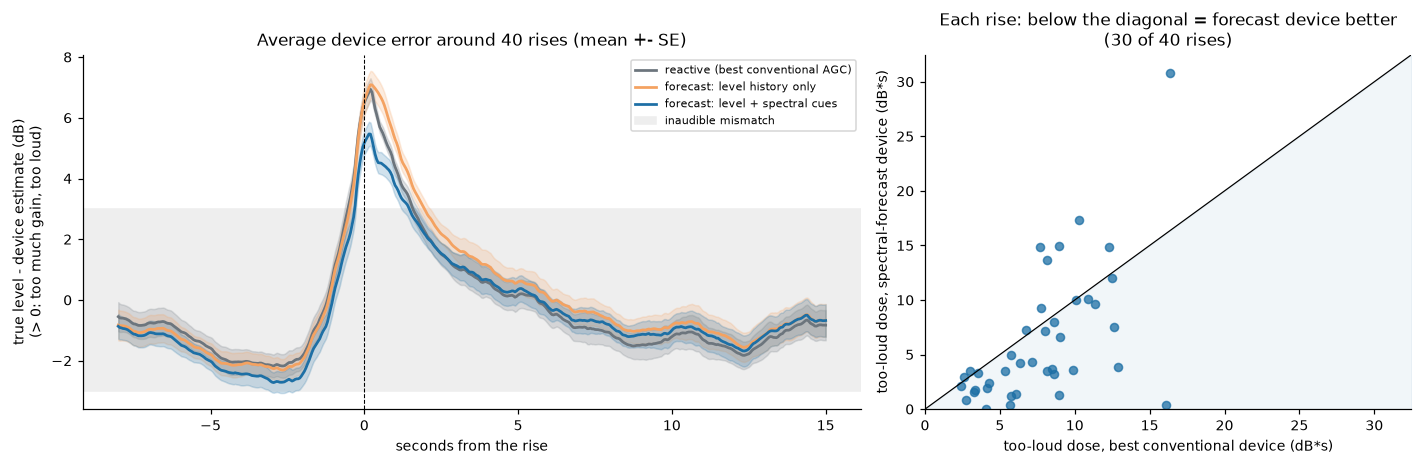

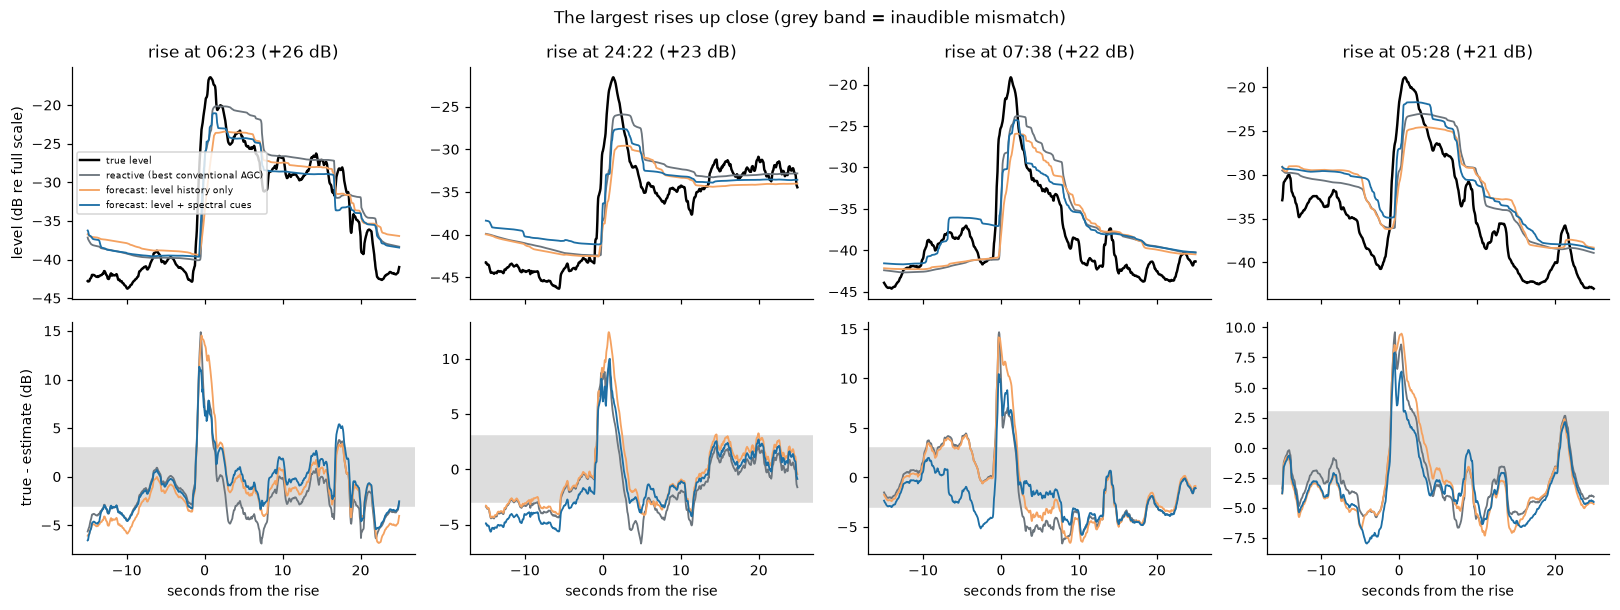

In [36]:
def plot_rise_locked(RISES, cfg):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw=dict(width_ratios=[1.6, 1]))
    n = len(RISES["onsets"])
    for f in FAMILIES:
        err = RISES["fam"][f]["err"]
        mu, se = err.mean(axis=0), err.std(axis=0) / np.sqrt(n)
        ax[0].fill_between(RISES["lags_s"], mu - se, mu + se, color=FAMILY_COLOR[f], alpha=0.2)
        ax[0].plot(RISES["lags_s"], mu, color=FAMILY_COLOR[f], lw=1.8, label=FAMILY_LABEL[f])
    ax[0].axhspan(-cfg["tolerance_db"], cfg["tolerance_db"], color="#eeeeee", label="inaudible mismatch", zorder=0)
    ax[0].axvline(0, color="k", ls="--", lw=0.7)
    ax[0].set_xlabel("seconds from the rise")
    ax[0].set_ylabel("true level - device estimate (dB)\n(> 0: too much gain, too loud)")
    ax[0].set_title(f"Average device error around {n} rises (mean +- SE)")
    ax[0].legend(fontsize=7)
    d_r, d_f = RISES["fam"]["reactive"]["dose"], RISES["fam"]["full"]["dose"]
    top = max(d_r.max(), d_f.max()) * 1.05 + 0.1
    ax[1].scatter(d_r, d_f, s=28, color=FAMILY_COLOR["full"], alpha=0.75)
    ax[1].plot([0, top], [0, top], color="k", lw=0.8)
    ax[1].fill_between([0, top], [0, 0], [0, top], color=FAMILY_COLOR["full"], alpha=0.06)
    ax[1].set_xlim(0, top)
    ax[1].set_ylim(0, top)
    ax[1].set_xlabel("too-loud dose, best conventional device (dB*s)")
    ax[1].set_ylabel("too-loud dose, spectral-forecast device (dB*s)")
    ax[1].set_title(f"Each rise: below the diagonal = forecast device better\n({int(np.sum(d_f < d_r))} of {n} rises)")
    fig.tight_layout()
    save_and_show(fig, "fig6_device_around_rises.png")

def plot_largest_rises(D, RISES, trajectory, cfg, n_show=4):
    order = np.argsort(-RISES["amp"])[:n_show]
    fig, axs = plt.subplots(2, len(order), figsize=(3.7 * len(order), 5.6), squeeze=False, sharex=True)
    before, after = secs(15, D["fs"]), secs(25, D["fs"])
    for c, k in enumerate(order):
        e = RISES["onsets"][k]
        window = slice(max(0, e - before), min(len(D["t"]), e + after))
        tt = D["t"][window] - D["t"][e]
        axs[0, c].plot(tt, D["L_ref"][window], color="k", lw=1.6, label="true level")
        for f in FAMILIES:
            axs[0, c].plot(tt, trajectory[f][window], color=FAMILY_COLOR[f], lw=1.2, label=FAMILY_LABEL[f])
            axs[1, c].plot(tt, D["L_ref"][window] - trajectory[f][window], color=FAMILY_COLOR[f], lw=1.2)
        axs[1, c].axhspan(-cfg["tolerance_db"], cfg["tolerance_db"], color="#dddddd", zorder=0)
        axs[0, c].set_title(f"rise at {mmss(D['t'][e])} (+{RISES['amp'][k]:.0f} dB)")
        axs[1, c].set_xlabel("seconds from the rise")
    axs[0, 0].set_ylabel("level (dB re full scale)")
    axs[1, 0].set_ylabel("true - estimate (dB)")
    axs[0, 0].legend(fontsize=6)
    fig.suptitle("The largest rises up close (grey band = inaudible mismatch)")
    fig.tight_layout()
    save_and_show(fig, "fig7_largest_rises.png")

if RISES is not None:
    plot_rise_locked(RISES, CFG)
    plot_largest_rises(D, RISES, trajectory, CFG)

## Summary

In [37]:
def to_json(o):
    if isinstance(o, dict):
        return {str(k): to_json(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_json(v) for v in o]
    if isinstance(o, np.ndarray):
        return to_json(o.tolist())
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (float, np.floating)):
        return float(o) if np.isfinite(o) else None
    if isinstance(o, np.bool_):
        return bool(o)
    return o

rows = []
rows.append(("Spectral cues give early warning from calm moments (1-4 s ahead)", f"strongest: {H2['best'][0]} at {H2['best'][1]:g} s, z = {H2['best'][3]:.1f}; beats {n_beaten} of " f"{len(zmax_null)} shifted-cue refits; family-wise p = {fmt_p(H2['p_omni'])}", "pre-specified test: " + ("**supported**" if supported else "not supported")))
for lead in H2["leads"]:
    cs = calm_rows[lead]["calm_surge"]
    if "auc_level" in cs:
        rows.append((f"Surge detection from calm moments, {lead:g} s ahead", f"AUC {cs['auc_level']:.2f} -> **{cs['auc_full']:.2f}** (gain CI {cs['diff_ci'][0]:+.2f} to " f"{cs['diff_ci'][1]:+.2f})", "estimate with CI"))
for s in skill:
    rows.append((f"Spectral cues improve the level forecast, {s['lead']:g} s ahead", f"added R2 **{s['all']['dr2']:+.3f}** [{s['all']['dr2_ci'][0]:+.3f}, {s['all']['dr2_ci'][1]:+.3f}]", "out-of-sample, bootstrap CI"))
rows.append(("Most informative spectral cue families", ", ".join(top[:2]), "descriptive"))
if RISES is not None:
    rows.append(("Too-loud exposure around big rises (medium-stability devices)", f"median {np.median(dose['reactive']):.1f} dBs conventional vs **{np.median(dose['full']):.1f} dBs** " f"spectral forecast; forecast device better in {wins_vs_reactive} of {n_rises} rises", "descriptive"))
lines = ["| finding | evidence | status |", "|---|---|---|"] + [f"| {a} | {b} | {c} |" for a, b, c in rows]
display(Markdown("\n".join(lines)))

summary = dict(config_hash=CONFIG_HASH, audio=[F["qc"] for F in audio_features], early_warning_test=H2, forecast_skill=skill, cue_importance=importance, rises=None if RISES is None else dict(n=n_rises, median_dose={f: float(np.median(dose[f])) for f in FAMILIES}, wins_vs_reactive=wins_vs_reactive, wins_vs_level=wins_vs_level), device_designs={f: C["picks"][MEDIUM][f]["label"] for f in FAMILIES}, config=CFG)
with open(os.path.join(OUT_DIR, "summary.json"), "w") as fh:
    json.dump(to_json(summary), fh, indent=1)
print(f"Saved summary.json and figures to {OUT_DIR}/  (config {CONFIG_HASH})")

| finding | evidence | status |
|---|---|---|
| Spectral cues give early warning from calm moments (1-4 s ahead) | strongest: AUC at 4 s, z = 5.5; beats 40 of 40 shifted-cue refits; family-wise p = 0.024 | pre-specified test: **supported** |
| Surge detection from calm moments, 1 s ahead | AUC 0.62 -> **0.73** (gain CI +0.05 to +0.19) | estimate with CI |
| Surge detection from calm moments, 2 s ahead | AUC 0.66 -> **0.77** (gain CI +0.04 to +0.18) | estimate with CI |
| Surge detection from calm moments, 4 s ahead | AUC 0.66 -> **0.79** (gain CI +0.08 to +0.19) | estimate with CI |
| Spectral cues improve the level forecast, 0.5 s ahead | added R2 **+0.051** [+0.016, +0.081] | out-of-sample, bootstrap CI |
| Spectral cues improve the level forecast, 1 s ahead | added R2 **+0.065** [+0.014, +0.113] | out-of-sample, bootstrap CI |
| Spectral cues improve the level forecast, 2 s ahead | added R2 **+0.094** [+0.031, +0.154] | out-of-sample, bootstrap CI |
| Spectral cues improve the level forecast, 4 s ahead | added R2 **+0.111** [+0.035, +0.192] | out-of-sample, bootstrap CI |
| Most informative spectral cue families | tonality, timbre | descriptive |
| Too-loud exposure around big rises (medium-stability devices) | median 7.9 dBs conventional vs **3.8 dBs** spectral forecast; forecast device better in 30 of 40 rises | descriptive |

Saved summary.json and figures to results/  (config 226a7c2a8694)


In [38]:
g = C["gains"]["full_vs_reactive"]
print(f"Whole-game audible mismatch, spectral-forecast device vs best conventional device at matched stability: "
      f"{g['est']:+.1f}% (95% CI {g['ci'][0]:+.1f} to {g['ci'][1]:+.1f}%; positive = forecast device better)")
for k, name in enumerate(C["showcase"]):
    print(f"  {name:<26} {g['showcase'][k]:+.1f}%  [{g['showcase_ci'][k][0]:+.1f}, {g['showcase_ci'][k][1]:+.1f}]")

Whole-game audible mismatch, spectral-forecast device vs best conventional device at matched stability: -24.0% (95% CI -36.3 to -13.6%; positive = forecast device better)
  fast (like a 2 s AGC)      -119.8%  [-145.9, -79.6]
  medium (like a 5 s AGC)    +11.5%  [-16.9, +17.5]
  slow (like a 15 s AGC)     +7.7%  [-5.3, +14.5]



## False-positive check

In [39]:
def env_shape(x, rise, hold, decay):
    out = np.zeros_like(x, dtype=float)
    up = (x >= 0) & (x < rise)
    out[up] = 0.5 - 0.5 * np.cos(np.pi * x[up] / rise)
    out[(x >= rise) & (x < rise + hold)] = 1.0
    dn = (x >= rise + hold) & (x < rise + hold + decay)
    out[dn] = 0.5 + 0.5 * np.cos(np.pi * (x[dn] - rise - hold) / decay)
    return out

In [40]:
def synth_game(path, minutes=32, sr=16000, seed=7, informative=True):
    import soundfile as sf
    from scipy.signal import butter, sosfilt, lfilter
    rng = np.random.default_rng(seed)
    dur = minutes * 60.0
    n = int(dur * sr)
    y = np.zeros(n, np.float32)

    def unit(x):
        return x / (np.sqrt(np.mean(np.square(x))) + 1e-12)

    def noise(m, lo, hi):
        return unit(sosfilt(butter(4, [lo, hi], btype="band", fs=sr, output="sos"), rng.standard_normal(m)))

    fe = 10.0
    ne = int(dur * fe) + 2
    tt = np.arange(ne) / fe

    def ar1(tau, sd):
        phi = np.exp(-1.0 / (tau * fe))
        return lfilter([np.sqrt(1 - phi ** 2) * sd], [1, -phi], rng.standard_normal(ne))

    bed_db = ar1(30.0, 3.0) + ar1(1.5, 1.5)
    s = 20.0
    while s < dur - 20:
        bed_db += rng.uniform(3, 7) * env_shape(tt - s, rng.uniform(1, 3), rng.uniform(1, 4), rng.uniform(2, 4))
        s += rng.uniform(10, 25)
    BED = 0.03
    sos_mid = butter(4, [200, 3000], btype="band", fs=sr, output="sos")
    sos_low = butter(4, [60, 180], btype="band", fs=sr, output="sos")
    k_mid = np.std(sosfilt(sos_mid, rng.standard_normal(5 * sr)))
    k_low = np.std(sosfilt(sos_low, rng.standard_normal(5 * sr)))
    z_mid, z_low = np.zeros((sos_mid.shape[0], 2)), np.zeros((sos_low.shape[0], 2))
    for a in range(0, n, 10 * sr):
        m = min(10 * sr, n - a)
        mid, z_mid = sosfilt(sos_mid, rng.standard_normal(m), zi=z_mid)
        low, z_low = sosfilt(sos_low, rng.standard_normal(m), zi=z_low)
        g = 10 ** (np.interp((a + np.arange(m)) / sr, tt, bed_db) / 20)
        y[a:a + m] = BED * g * (mid / k_mid + 0.5 * low / k_low)

    def bed_rms(t):
        return BED * 1.118 * 10 ** (np.interp(t, tt, bed_db) / 20)

    def add(sig, start):
        a = int(round(start * sr))
        b = min(n, a + len(sig))
        if a >= 0 and b > a:
            y[a:b] += sig[:b - a].astype(np.float32)

    def roar(t_on):
        rise, hold, decay = rng.uniform(0.6, 1.8), rng.uniform(3, 8), rng.uniform(2, 5)
        x = np.arange(int((rise + hold + decay) * sr)) / sr
        env = env_shape(x, rise, hold, decay) * (1 + 0.15 * np.sin(2 * np.pi * 0.7 * x))
        add(bed_rms(t_on) * np.sqrt(10 ** (rng.uniform(8, 18) / 10) - 1) * env * noise(len(x), 250, 2500), t_on)

    def music(t_on):
        length, rise, fade = rng.uniform(6, 14), rng.uniform(0.15, 0.4), rng.uniform(1, 2)
        x = np.arange(int((length + fade) * sr)) / sr
        beat = 0.5
        kick = np.sin(2 * np.pi * 60 * x) * np.exp(-(x % beat) / 0.08)
        root = np.where((x // (2 * beat)) % 2 == 0, 55.0, 73.4)
        bass = np.sin(2 * np.pi * np.cumsum(root) / sr)
        chord = sum(np.sin(2 * np.pi * f * k * x) / k for f in (220.0, 277.2, 329.6) for k in (1, 2, 3, 4))
        hats = noise(len(x), 5000, 7500) * np.exp(-(x % (beat / 2)) / 0.02)
        sig = 0.6 * unit(kick + 0.7 * bass) + 0.6 * unit(chord) + 0.3 * unit(hats)
        env = env_shape(x, rise, length - rise, fade)
        add(bed_rms(t_on) * np.sqrt(10 ** (rng.uniform(8, 16) / 10) - 1) * env * unit(sig), t_on)

    def announcer(start, length):
        x = np.arange(int(length * sr)) / sr
        f0 = rng.uniform(105, 140) * (1 + 0.08 * np.sin(2 * np.pi * rng.uniform(0.3, 0.8) * x))
        phase = 2 * np.pi * np.cumsum(f0) / sr
        voice = np.zeros(len(x))
        for k in range(1, 28):
            fk = k * f0.mean()
            w = (np.exp(-((fk - 600) / 250) ** 2) + 0.6 * np.exp(-((fk - 1500) / 350) ** 2)
                 + 0.4 * np.exp(-((fk - 2600) / 400) ** 2) + 0.05)
            voice += w * np.sin(k * phase)
        syll, s0 = np.zeros(len(x)), 0.0
        while s0 < length:
            d = rng.uniform(0.12, 0.28)
            syll += env_shape(x - s0, 0.3 * d, 0.4 * d, 0.3 * d)
            s0 += d + rng.uniform(0.03, 0.10)
        add(bed_rms(start) * 10 ** (rng.uniform(-6, -2) / 20) * unit(voice * syll), start)

    def whistle(start):
        for _ in range(int(rng.integers(1, 3))):
            length = rng.uniform(0.25, 0.5)
            x = np.arange(int(length * sr)) / sr
            f = rng.uniform(3000, 3800) + 80 * np.sin(2 * np.pi * 28 * x)
            tone = np.sin(2 * np.pi * np.cumsum(f) / sr) * env_shape(x, 0.02, length - 0.06, 0.04)
            add(bed_rms(start) * 10 ** (rng.uniform(-6, -2) / 20) * np.sqrt(2) * tone, start)
            start += length + 0.15

    def cue(kind, t_on):
        if kind == "roar":
            whistle(t_on - rng.uniform(1.0, 2.5))
        else:
            length = rng.uniform(1.8, 3.0)
            announcer(t_on - rng.uniform(0.3, 1.2) - length, length)

    events = []
    t_on = 50.0
    while t_on < dur - 40:
        events.append((t_on, "roar" if rng.random() < 0.5 else "music"))
        t_on += rng.uniform(35, 90)
    on_times = np.array([e[0] for e in events])
    n_cued = 0
    for t_on, kind in events:
        if informative and rng.random() < 0.85:
            cue(kind, t_on)
            n_cued += 1
        (roar if kind == "roar" else music)(t_on)
    n_random = int(round(0.20 * len(events))) if informative else int(round(1.05 * len(events)))
    placed = 0
    while placed < n_random:
        t_c = rng.uniform(40, dur - 30)
        if informative and np.min(np.abs(on_times - t_c)) < 15:
            continue                              # false alarms are not allowed near real events
        cue("roar" if rng.random() < 0.5 else "music", t_c)
        placed += 1
    y *= 0.7 / np.abs(y).max()
    sf.write(path, y, sr, subtype="PCM_16")
    print(f"  synthetic: {minutes} min, {len(events)} big events "
          f"({sum(k == 'roar' for _, k in events)} roars / {sum(k == 'music' for _, k in events)} music), "
          f"{n_cued} cued + {n_random} cues at random times, cues informative={informative}")
    return dict(events=events, informative=informative)

In [42]:
def early_warning_test_on(files, out_dir, cfg):
    os.makedirs(out_dir, exist_ok=True)
    recs = [build_recording(load_or_extract(p, out_dir, cfg, True), cfg, LEADS) for p in files]
    D_ = combine(recs, cfg, LEADS)
    splits_ = make_splits(D_, cfg, max(LEADS))
    preds_ = {}
    for lead in cfg["anticipation_leads_sec"]:
        y = D_["targets"][lead]
        p_level, clim, _ = oof_forecast(D_["X"][:, D_["level_cols"]], y, splits_, cfg)
        p_full, _, _ = oof_forecast(D_["X"], y, splits_, cfg)
        preds_[lead] = dict(level=p_level, full=p_full, clim=clim)
    return anticipation_test(D_, splits_, preds_, cfg, np.random.default_rng(cfg["seed"]))


RUN_FALSE_POSITIVE_CHECK = True
if RUN_FALSE_POSITIVE_CHECK:
    null_dir = os.path.join(OUT_DIR, "appendix_null_check")
    os.makedirs(null_dir, exist_ok=True)
    wav = os.path.join(null_dir, "synthetic_random_cues.wav")
    synth_game(wav, minutes=32, seed=7, informative=False)
    H2_null = early_warning_test_on([wav], null_dir, CFG)
    ok = not (H2_null["best_positive"] and H2_null["p_omni"] <= 0.05)
    print(f"Random cues: strongest z = {H2_null['best'][3]:.1f}, permutation p = {fmt_p(H2_null['p_omni'])} -> "
          f"{'PASS (no false early warning)' if ok else 'FAIL'}")
else:
    print("Skipped (set RUN_FALSE_POSITIVE_CHECK = True to run it).")

  synthetic: 32 min, 29 big events (11 roars / 18 music), 0 cued + 30 cues at random times, cues informative=False
  synthetic_random_cues.wav: 32.0 min, 16000 Hz, 38397 frames x 21 bands in 8s
    refit 5/40 (96s)
    refit 10/40 (191s)
    refit 15/40 (285s)
    refit 20/40 (380s)
    refit 25/40 (474s)
    refit 30/40 (568s)
    refit 35/40 (663s)
    refit 40/40 (757s)
Random cues: strongest z = 2.0, permutation p = 0.073 -> PASS (no false early warning)
